# 06 — Telco: Feature engineering and data representation
**Session 4 · Objective:** Ask whether better inputs help a fixed model, then compare complete solutions without confusing the effects of algorithm and representation.

Same development customers, five stratified folds and Average Precision (AP). The final 20% test stays closed. All examples and experiments use Telco.

In [1]:
from pathlib import Path
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import scipy
import xgboost
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (StandardScaler, OneHotEncoder, TargetEncoder,
                                   KBinsDiscretizer, PolynomialFeatures)
from xgboost import XGBClassifier

# Keep the actual execution environment visible alongside the results.
print({"Python": platform.python_version(), "NumPy": np.__version__,
       "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
       "SciPy": scipy.__version__, "XGBoost": xgboost.__version__})
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False})

{'Python': '3.12.9', 'NumPy': '2.5.3', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'SciPy': '1.18.1', 'XGBoost': '3.4.1'}


## Rebuild the experiment
Use the exact dataset and split from class and notebook 03. `SeniorCitizen` remains categorical. AP measures ranking quality; fold standard deviation describes variation, not a confidence interval.

In [2]:
# Run from notebooks/, as in the earlier notebooks.
data_path = Path("../data/telco.csv")
fingerprint = hashlib.sha256(data_path.read_bytes()).hexdigest()
class_fingerprint = "88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a"
assert fingerprint == class_fingerprint, "Dataset differs from class; investigate before comparing figures."
print("Dataset SHA-256:", fingerprint)
df = pd.read_csv(data_path)
# Parsing is deterministic. Learned imputation stays inside the Pipeline.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].eq("Yes").astype(int)
# Preserve classroom development order, including the stable ranking tie rule.
dev, locked = train_test_split(np.arange(len(df)), test_size=0.20, stratify=y, random_state=42)
X_dev = X.iloc[dev].reset_index(drop=True)
y_dev = y.iloc[dev].reset_index(drop=True)
# Locked indices never enter fitting, scoring or decisions below.
folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(X_dev, y_dev))
assert set(dev).isdisjoint(locked)
print(f"Development: {len(dev):,}; locked final test: {len(locked):,}")

Dataset SHA-256: 88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a
Development: 5,634; locked final test: 1,409


## What hypothesis does each representation test?
New columns must be available at prediction time. Telco is a historical snapshot: these experiments do not establish that a billing pattern causes churn.

| Set | Changes relative to original inputs | Hypothesis |
|---|---|---|
| raw | Three numeric fields + one-hot categories | Reference from notebook 03 |
| ratio | Add TotalCharges / tenure | Historical monthly spending may expose a useful relative level |
| buckets | Keep ratio; add four tenure quantile indicators | Early and established customers may behave differently |
| interactions | Keep ratio and buckets; add monthly-contract × tenure and × MonthlyCharges | Tenure and spending may matter differently for flexible contracts |
| everything | Keep previous terms; add two logs and six degree-2 terms | Combine proposed nonlinear relationships |
| logs_only | raw + log1p(tenure), log1p(TotalCharges) | Early changes may matter more than later changes |
| poly_only | raw + squares and pairwise products of three standardized numeric fields | Smooth curvature and interactions may help |
| extended | everything, replacing one-hot with smoothed target encoding | A compact outcome-based representation may help |

These names match the slides: `logs_only` **adds** logs and retains the original variables. Ratio, buckets and interactions form a cumulative sequence; compare `logs_only` and `poly_only` with raw to isolate those additions. More columns need not improve validation AP.

## Make the transformations explicit
The ratio is undefined at zero tenure; use missing rather than an artificial tiny denominator. Impute within training. Logs and contract products operate row by row. Quantile boundaries, frequencies, target rates, medians and scaling statistics must be learned separately inside every training fold.

The degree-2 branch standardizes before forming products and scales the resulting terms. This matters for regularized Logistic Regression. The original numeric branch remains present.

In [3]:
NUM = ['tenure', 'MonthlyCharges', 'TotalCharges']
SETS = ['raw', 'ratio', 'buckets', 'interactions', 'everything', 'logs_only', 'poly_only', 'extended']

class DomainFeatures(TransformerMixin, BaseEstimator):
    def __init__(self, feature_set='raw'):
        self.feature_set = feature_set
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        z = X.copy()
        if self.feature_set in ('ratio', 'buckets', 'interactions', 'everything', 'extended'):
            # Zero tenure means the historical monthly average is undefined.
            z['historical_monthly'] = z['TotalCharges'] / z['tenure'].replace(0, np.nan)
        if self.feature_set in ('interactions', 'everything', 'extended'):
            monthly = z['Contract'].eq('Month-to-month').astype(float)
            z['monthly_x_tenure'] = monthly * z['tenure']
            z['monthly_x_charge'] = monthly * z['MonthlyCharges']
        if self.feature_set in ('everything', 'logs_only', 'extended'):
            z['log_tenure'] = np.log1p(z['tenure'])
            z['log_total'] = np.log1p(z['TotalCharges'])
        return z

class FrequencyEncoder(TransformerMixin, BaseEstimator):
    def fit(self, X, y=None):
        frame = pd.DataFrame(X)
        self.maps_ = [frame[c].value_counts(normalize=True, dropna=False).to_dict() for c in frame]
        return self
    def transform(self, X):
        frame = pd.DataFrame(X)
        return np.column_stack([frame[c].map(self.maps_[i]).fillna(0).to_numpy() for i,c in enumerate(frame)])

### Keep all learned steps inside the Pipeline
One-hot preserves identity without ordering categories. Frequency encoding uses training prevalence (unseen categories map to zero here), so equally frequent categories become indistinguishable. Target encoding uses smoothed churn rates (`smooth=10`): useful compression is a hypothesis, not a promise.

`TargetEncoder.fit_transform` internally cross-fits **training** encodings with five shuffled folds (seed 42). Validation encodings use only the outer training data. Calling `fit` then `transform` on the same training rows would bypass that internal protection. The Pipeline uses `fit_transform` correctly.

Session 4 specifies XGBoost depth **2**, histogram trees, 100 estimators and learning rate 0.1. Notebook 05 used depth 3. We preserve both lessons and do not attribute a change between their scores solely to features.

In [4]:
def build_pipeline(X, feature_set='raw', model='Logistic', encoding='onehot'):
    nums = list(NUM)
    if feature_set in ('ratio', 'buckets', 'interactions', 'everything', 'extended'):
        nums += ['historical_monthly']
    if feature_set in ('interactions', 'everything', 'extended'):
        nums += ['monthly_x_tenure', 'monthly_x_charge']
    if feature_set in ('everything', 'logs_only', 'extended'):
        nums += ['log_tenure', 'log_total']
    cats = [c for c in X.columns if c not in NUM]
    if feature_set == 'extended':
        encoding = 'target'
    enc = {'onehot': OneHotEncoder(handle_unknown='ignore'),
           'frequency': FrequencyEncoder(),
           'target': TargetEncoder(target_type='binary', smooth=10.0,
                                   cv=StratifiedKFold(5, shuffle=True, random_state=42))}[encoding]
    numeric = Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
    branches = [('num', numeric, nums), ('cat', enc, cats)]
    if feature_set in ('buckets', 'interactions', 'everything', 'extended'):
        branches.append(('bins', KBinsDiscretizer(n_bins=4, encode='onehot', strategy='quantile',
                            quantile_method='linear', subsample=None, random_state=42), ['tenure']))
    if feature_set in ('everything', 'poly_only', 'extended'):
        poly = Pipeline([('impute', SimpleImputer(strategy='median')),
                         ('scale_input', StandardScaler()),
                         ('degree2', PolynomialFeatures(degree=(2,2), include_bias=False)),
                         ('scale_terms', StandardScaler())])
        branches.append(('poly', poly, NUM))
    classifier = (LogisticRegression(max_iter=2000) if model == 'Logistic' else
                  XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=2,
                                tree_method='hist', eval_metric='logloss', random_state=42, n_jobs=1))
    return Pipeline([('features', DomainFeatures(feature_set)),
                     ('preprocess', ColumnTransformer(branches, remainder='drop')),
                     ('model', classifier)])

## Observe the changed information
Inspect only development rows. A log compresses large values; adding it lets the linear score express a different shape.

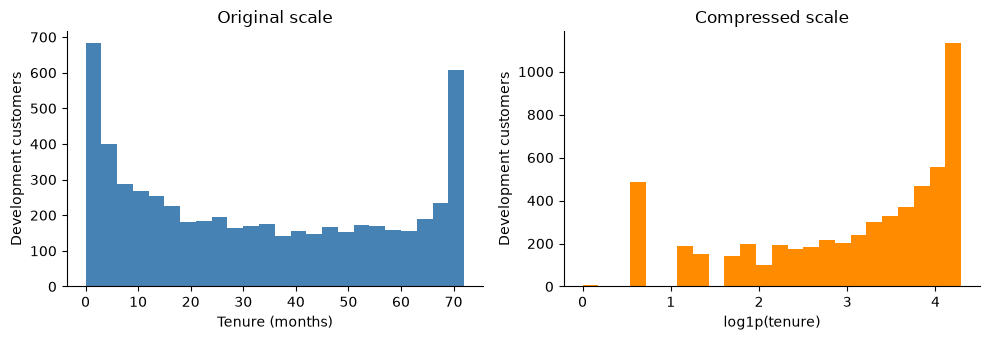

,min,Q1,median,Q3,max
1,0.0,9.0,29.0,55.0,72.0
2,0.0,9.0,29.0,55.0,72.0
3,0.0,9.0,29.0,56.0,72.0
4,0.0,9.0,29.0,55.0,72.0
5,0.0,9.0,29.0,56.0,72.0


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(X_dev["tenure"], bins=24, color="steelblue")
axes[0].set(xlabel="Tenure (months)", ylabel="Development customers", title="Original scale")
axes[1].hist(np.log1p(X_dev["tenure"]), bins=24, color="darkorange")
axes[1].set(xlabel="log1p(tenure)", ylabel="Development customers", title="Compressed scale")
plt.tight_layout()
plt.show()
# Learn bin edges separately from each training partition.
edges = []
for tr, va in folds:
    bins = KBinsDiscretizer(n_bins=4, encode="onehot", strategy="quantile",
                           quantile_method="linear", subsample=None, random_state=42)
    bins.fit(X_dev.iloc[tr][["tenure"]])
    edges.append(bins.bin_edges_[0])
display(pd.DataFrame(edges, index=range(1, 6), columns=["min", "Q1", "median", "Q3", "max"]))

A possible Telco difference feature is `MonthlyCharges - historical_monthly`: it asks how far current charges are above the historical average. It does not establish a price increase. Once both operands are present, a linear model can already express their difference; adding it also changes regularization. We do not claim a measured AP improvement for this untested feature.

## Run the same experiment for every representation
Each fit starts with a fresh Pipeline. Store all five APs and transformed widths. Compare rows within an algorithm to study representation; compare algorithms at a fixed representation to study the classifier.

In [6]:
def evaluate(pipe):
    scores, widths = [], []
    for tr, va in folds:
        fitted = clone(pipe).fit(X_dev.iloc[tr], y_dev.iloc[tr])
        p = fitted.predict_proba(X_dev.iloc[va])[:, 1]
        scores.append(average_precision_score(y_dev.iloc[va], p))
        widths.append(fitted[:-1].transform(X_dev.iloc[va]).shape[1])
    return np.array(scores), widths

results, rows = {}, []
for model in ("Logistic", "XGBoost"):
    for feature_set in SETS:
        scores, widths = evaluate(build_pipeline(X_dev, feature_set, model))
        results[model, feature_set] = scores
        rows.append({"Model": model, "Representation": feature_set,
                     **{f"Fold {i}": v for i, v in enumerate(scores, 1)},
                     "Mean AP": scores.mean(), "Fold std": scores.std(ddof=1),
                     "Columns (each fold)": str(widths)})
comparison = pd.DataFrame(rows).set_index(["Model", "Representation"])
display(comparison.round(6))

Fold 1    Fold 2    Fold 3    Fold 4    Fold 5  \
Model    Representation                                                     
Logistic raw             0.643523  0.635589  0.685717  0.678189  0.664162   
         ratio           0.644552  0.634710  0.682597  0.673419  0.662906   
         buckets         0.643719  0.647394  0.673638  0.673011  0.674930   
         interactions    0.643356  0.647464  0.676246  0.675153  0.673989   
         everything      0.652618  0.648371  0.695216  0.677325  0.683451   
         logs_only       0.652116  0.653670  0.693201  0.682721  0.680908   
         poly_only       0.650359  0.650579  0.686488  0.676986  0.673903   
         extended        0.647754  0.638212  0.687216  0.672031  0.685218   
XGBoost  raw             0.654608  0.631606  0.691279  0.686818  0.679212   
         ratio           0.655431  0.631457  0.691123  0.682757  0.676336   
         buckets         0.655431  0.631457  0.691123  0.682757  0.676336   
         interactions    0.653194  0.629900  0.692748  0.682766  0.678931   
         everything      0.653696  0.639480  0.697725  0.682359  0.683069   
         logs_only       0.654608  0.631606  0.691279  0.686818  0.679212   
         poly_only       0.652688  0.640339  0.700809  0.688672  0.678604   
         extended        0.649186  0.632877  0.696317  0.674367  0.683469   

                          Mean AP  Fold std   Columns (each fold)  
Model    Representation                                            
Logistic raw             0.661436  0.021602  [46, 46, 46, 46, 46]  
         ratio           0.659637  0.019854  [47, 47, 47, 47, 47]  
         buckets         0.662539  0.015572  [51, 51, 51, 51, 51]  
         interactions    0.663242  0.016362  [53, 53, 53, 53, 53]  
         everything      0.671396  0.020191  [61, 61, 61, 61, 61]  
         logs_only       0.672523  0.018532  [48, 48, 48, 48, 48]  
         poly_only       0.667663  0.016367  [52, 52, 52, 52, 52]  
         extended        0.666086  0.022141  [34, 34, 34, 34, 34]  
XGBoost  raw             0.668705  0.025115  [46, 46, 46, 46, 46]  
         ratio           0.667421  0.024050  [47, 47, 47, 47, 47]  
         buckets         0.667421  0.024050  [51, 51, 51, 51, 51]  
         interactions    0.667508  0.025591  [53, 53, 53, 53, 53]  
         everything      0.671266  0.023883  [61, 61, 61, 61, 61]  
         logs_only       0.668705  0.025115  [48, 48, 48, 48, 48]  
         poly_only       0.672222  0.025133  [52, 52, 52, 52, 52]  
         extended        0.667243  0.025819  [34, 34, 34, 34, 34]

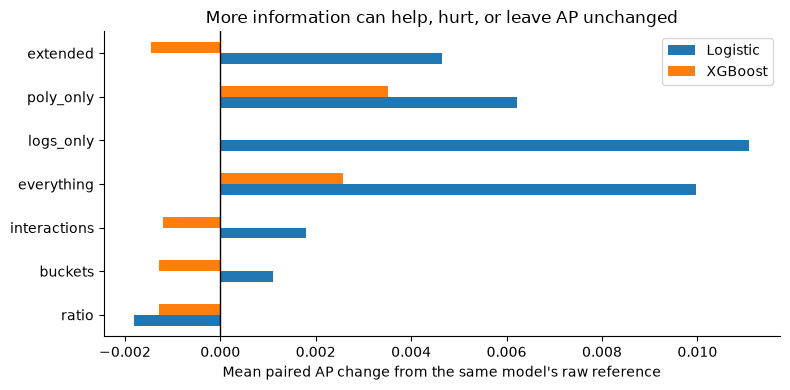

In [7]:
# Compare against each algorithm's own raw reference.
changes = pd.DataFrame({model: {s: (results[model, s] - results[model, "raw"]).mean()
                               for s in SETS if s != "raw"}
                        for model in ("Logistic", "XGBoost")})
changes.plot.barh()
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Mean paired AP change from the same model's raw reference")
plt.title("More information can help, hurt, or leave AP unchanged")
plt.tight_layout()
plt.show()

## Does categorical compression help on Telco?
Keep raw inputs, Logistic Regression, folds, metric and regularization fixed. Only the categorical representation changes. Telco has few levels per field; there is no high-cardinality benefit to assume.

In [8]:
encoding_rows = []
for encoding in ("onehot", "frequency", "target"):
    scores, widths = evaluate(build_pipeline(X_dev, encoding=encoding))
    encoding_rows.append({"Encoding": encoding, "Mean AP": scores.mean(),
                          "Fold std": scores.std(ddof=1), "Columns": str(widths),
                          **{f"Fold {i}": v for i, v in enumerate(scores, 1)}})
display(pd.DataFrame(encoding_rows).set_index("Encoding").round(6))

,Mean AP,Fold std,Columns,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
Encoding,,,,,,,,
onehot,0.661436,0.021602,"[46, 46, 46, 46, 46]",0.643523,0.635589,0.685717,0.678189,0.664162
frequency,0.660465,0.017545,"[19, 19, 19, 19, 19]",0.643228,0.640315,0.672447,0.678733,0.667601
target,0.656384,0.016692,"[19, 19, 19, 19, 19]",0.638742,0.639001,0.668389,0.674676,0.661114


## Read the result before choosing a winner
Class reference means: Logistic raw **0.661436**, +logs **0.672523**, all combined **0.671396**; XGBoost raw **0.668705**, +degree-2 **0.672222**. The executed table gives results in this environment; small numeric differences can arise from library versions.

The ratio has a sensible interpretation but did not improve mean AP. Two added logs beat the larger Logistic combined sets; target encoding is compact but weaker here. XGBoost can learn thresholds itself, so explicitly adding tenure buckets need not change predictions.

Logistic +logs versus XGBoost +polynomials compares **complete solutions**, changing algorithm and representation. The tiny mean gap cannot be credited to the algorithm alone. Repeatedly consulting this table can overfit development evidence; notebook 07 studies that risk.

Session 4 quoted +€127,796 per million for Logistic raw versus Logistic +logs, using training predictions and assumed campaign economics. Notebook 08 recomputes that claim with out-of-fold predictions and uncertainty. AP differences do not directly translate into euros.

**Takeaway:** Start from a hypothesis, hold the evaluation protocol fixed, and keep failures visible. No final-test result has been used.

Implementation reference: [scikit-learn TargetEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.TargetEncoder.html), including internal cross-fitting.